<a href="https://colab.research.google.com/github/yashii24/Land-use-classification/blob/main/Land_use_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!rm -rf /root/tensorflow_datasets/uc_merced

In [3]:
!pip install -q importlib_resources

README.md:   0%|          | 0.00/2.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  416MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2100 [00:00<?, ? examples/s]

Images: 2100
Classes: 21
['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


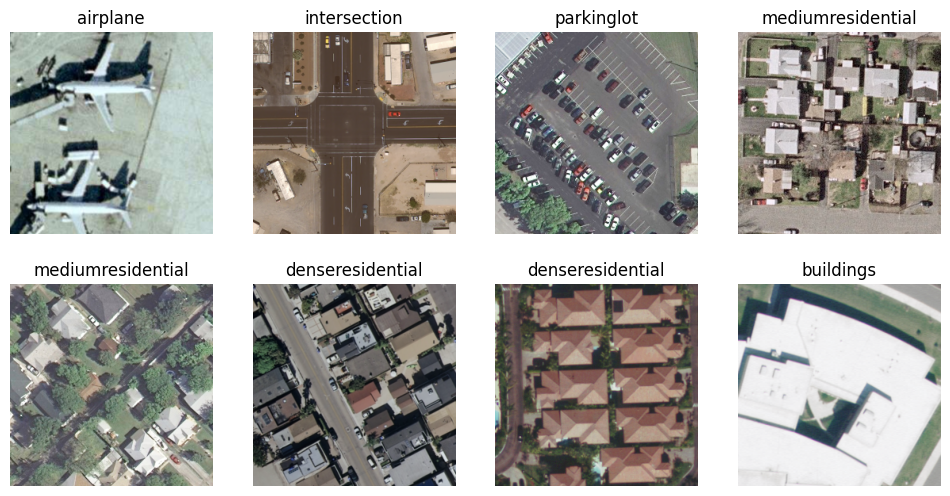

In [5]:
!pip install -q datasets

from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

raw = load_dataset("blanchon/UC_Merced", split="train")
class_names = raw.features["label"].names

print("Images:", len(raw))
print("Classes:", len(class_names))
print(class_names)


plt.figure(figsize=(12, 6))
for k, i in enumerate(np.random.choice(len(raw), 8, replace=False)):
    ex = raw[int(i)]
    plt.subplot(2, 4, k + 1)
    plt.imshow(ex["image"])
    plt.title(class_names[ex["label"]])
    plt.axis("off")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

IMG_SIZE = 224

x = np.stack([np.array(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))) for img in raw["image"]])
y = np.array(raw["label"])
print(x.shape, y.shape)


x_train, x_tmp, y_train, y_tmp = train_test_split(x, y, test_size=0.30, stratify=y, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)
print(len(x_train), len(x_val), len(x_test))   # expect 1470 315 315

(2100, 224, 224, 3) (2100,)
1470 315 315


In [7]:
import tensorflow as tf


augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.25),
])


base = tf.keras.applications.EfficientNetV2B0(
    include_top=False, weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
base.trainable = False

inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
h = augment(inputs)
h = base(h, training=False)
h = tf.keras.layers.GlobalAveragePooling2D()(h)
h = tf.keras.layers.Dropout(0.3)(h)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(h)
model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Model built. Trainable params:", sum(tf.size(w).numpy() for w in model.trainable_weights))

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model built. Trainable params: 26901


In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history1 = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10, batch_size=32,
    callbacks=callbacks,
)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 26s 217ms/step - accuracy: 0.5048 - loss: 1.9467 - val_accuracy: 0.8286 - val_loss: 1.0802 - learning_rate: 0.0010
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.8231 - loss: 0.8579 - val_accuracy: 0.9079 - val_loss: 0.6120 - learning_rate: 0.0010
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.8891 - loss: 0.5614 - val_accuracy: 0.9270 - val_loss: 0.4488 - learning_rate: 0.0010
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9109 - loss: 0.4344 - val_accuracy: 0.9460 - val_loss: 0.3619 - learning_rate: 0.0010
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.9204 - loss: 0.3612 - val_accuracy: 0.9524 - val_loss: 0.3112 - learning_rate: 0.0010
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9395 - loss: 0.2975 - val_accuracy: 0.9397 - val_loss: 0.2735 - learning_rate: 0.0010
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.9395 - loss: 0.2703 - val_a

46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9544 - loss: 0.2415 - val_accuracy: 0.9556 - val_loss: 0.2223 - learning_rate: 0.0010
Epoch 9/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.9476 - loss: 0.2168 - val_accuracy: 0.9619 - val_loss: 0.2068 - learning_rate: 0.0010
Epoch 10/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9578 - loss: 0.1981 - val_accuracy: 0.9492 - val_loss: 0.1952 - learning_rate: 0.0010


In [9]:
base.trainable = True


for layer in base.layers[:-60]:
    layer.trainable = False

for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False


model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history2 = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20, batch_size=32,
    callbacks=callbacks,
)

Epoch 1/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 27s 283ms/step - accuracy: 0.9605 - loss: 0.1790 - val_accuracy: 0.9619 - val_loss: 0.1755 - learning_rate: 1.0000e-05
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.9551 - loss: 0.1807 - val_accuracy: 0.9587 - val_loss: 0.1590 - learning_rate: 1.0000e-05
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.9619 - loss: 0.1468 - val_accuracy: 0.9619 - val_loss: 0.1489 - learning_rate: 1.0000e-05
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.9626 - loss: 0.1428 - val_accuracy: 0.9587 - val_loss: 0.1410 - learning_rate: 1.0000e-05


10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 385ms/step
Test accuracy: 0.9460

                   precision    recall  f1-score   support

     agricultural      1.000     1.000     1.000        15
         airplane      1.000     1.000     1.000        15
  baseballdiamond      1.000     1.000     1.000        15
            beach      1.000     1.000     1.000        15
        buildings      0.875     0.933     0.903        15
        chaparral      1.000     1.000     1.000        15
 denseresidential      0.909     0.667     0.769        15
           forest      1.000     1.000     1.000        15
          freeway      1.000     0.933     0.966        15
       golfcourse      1.000     0.933     0.966        15
           harbor      1.000     1.000     1.000        15
     intersection      0.778     0.933     0.848        15
mediumresidential      0.824     0.933     0.875        15
   mobilehomepark      1.000     0.933     0.966        15
         overpass      0.933     0.933     0.933  

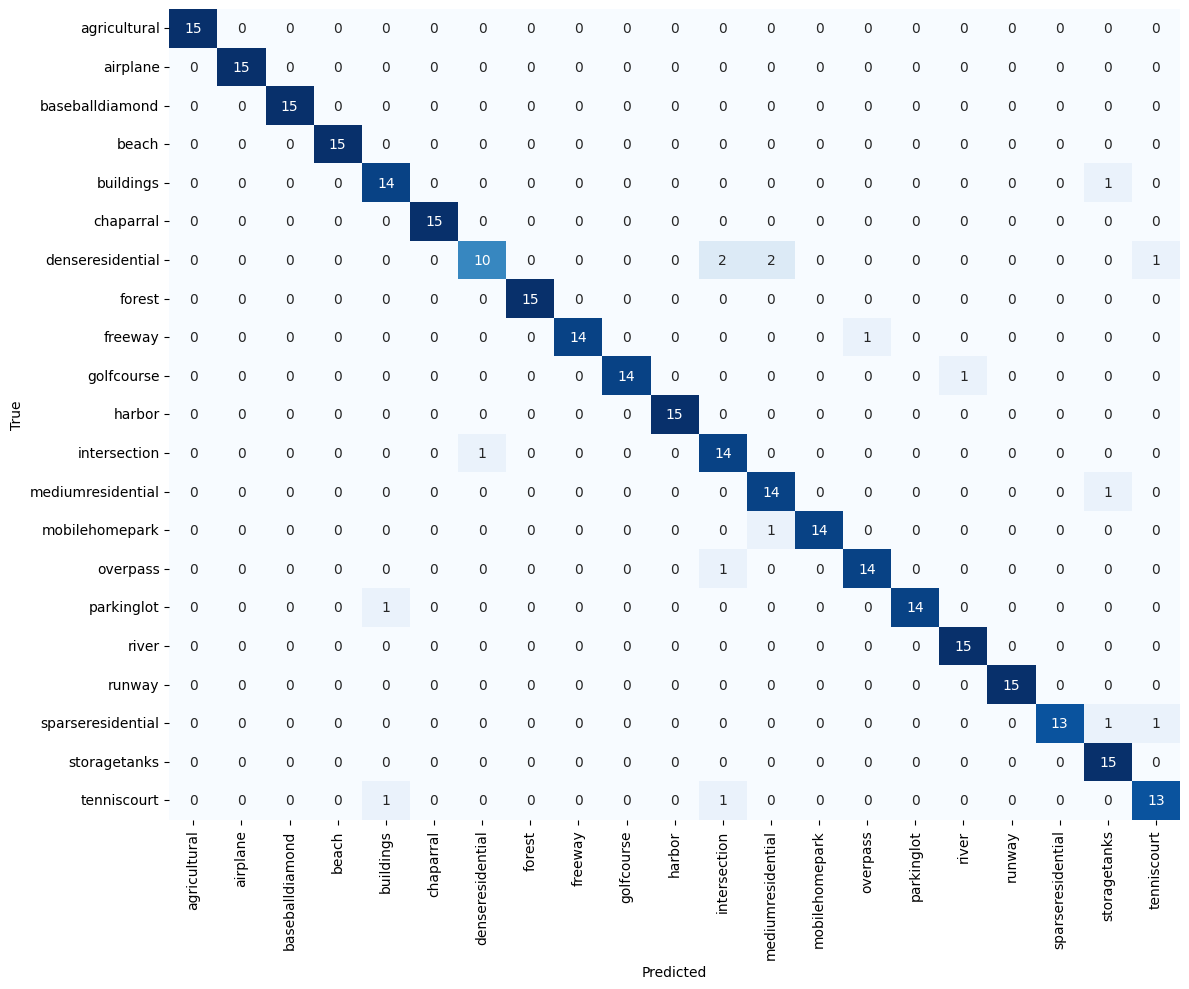

In [10]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

probs = model.predict(x_test, batch_size=32)
preds = probs.argmax(axis=1)
print(f"Test accuracy: {(preds == y_test).mean():.4f}\n")
print(classification_report(y_test, preds, target_names=class_names, digits=3))

cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

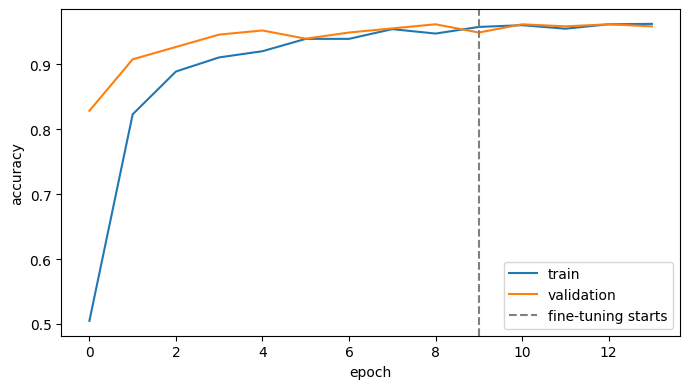

Mounted at /content/drive
Saved.


In [12]:

acc = history1.history["accuracy"] + history2.history["accuracy"]
val = history1.history["val_accuracy"] + history2.history["val_accuracy"]
plt.figure(figsize=(7, 4))
plt.plot(acc, label="train")
plt.plot(val, label="validation")
plt.axvline(len(history1.history["accuracy"]) - 1, ls="--", c="gray", label="fine-tuning starts")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()


with open("classification_report.txt", "w") as f:
    f.write(f"Test accuracy: {(preds == y_test).mean():.4f}\n\n")
    f.write(classification_report(y_test, preds, target_names=class_names, digits=3))


from google.colab import drive
drive.mount("/content/drive")
model.save("/content/drive/MyDrive/land_use_model.keras")
print("Saved.")